findfont: Failed to find font weight bold for MS Gothic, now using 400.


-> Qwen_LR_trajectory_Human_All.png を保存しました。


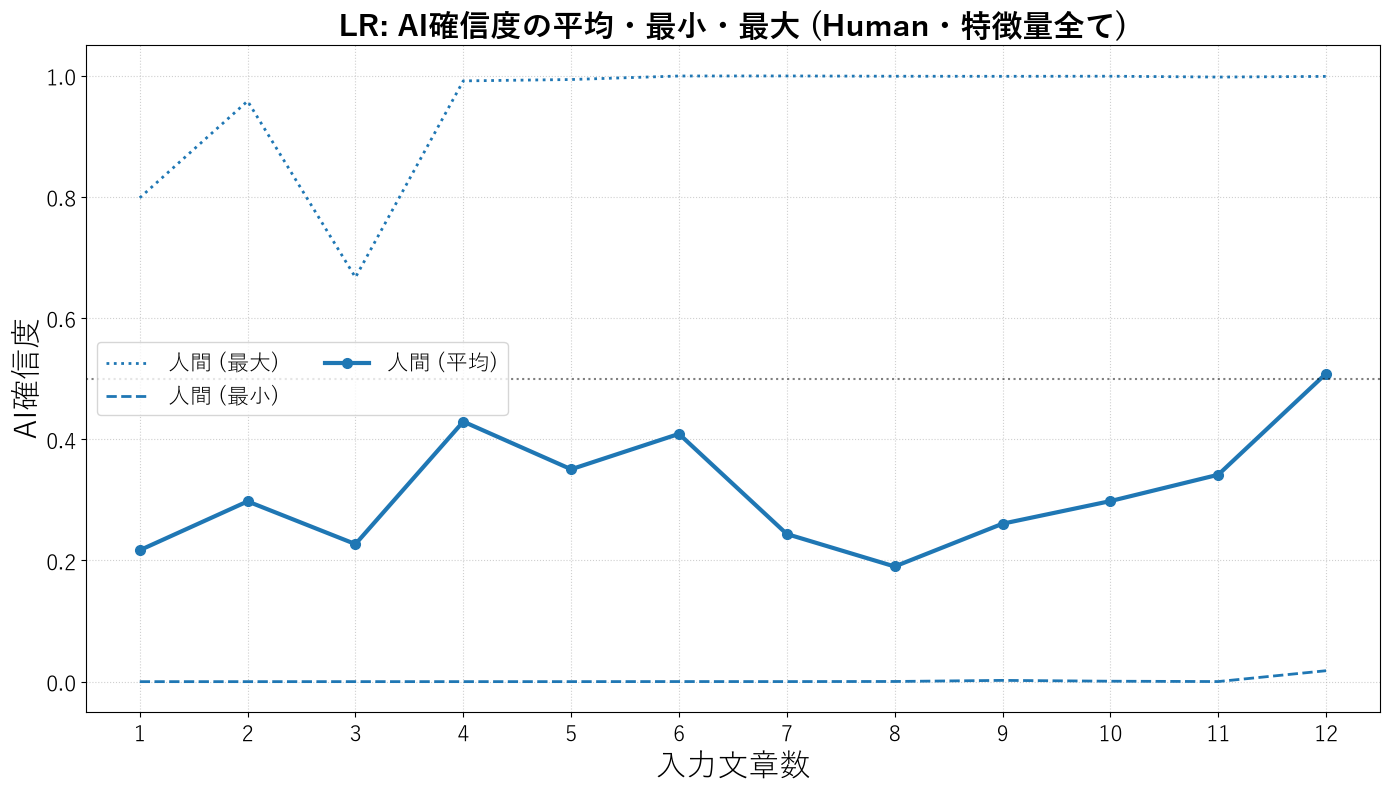

-> Qwen_LR_trajectory_Human_Function.png を保存しました。


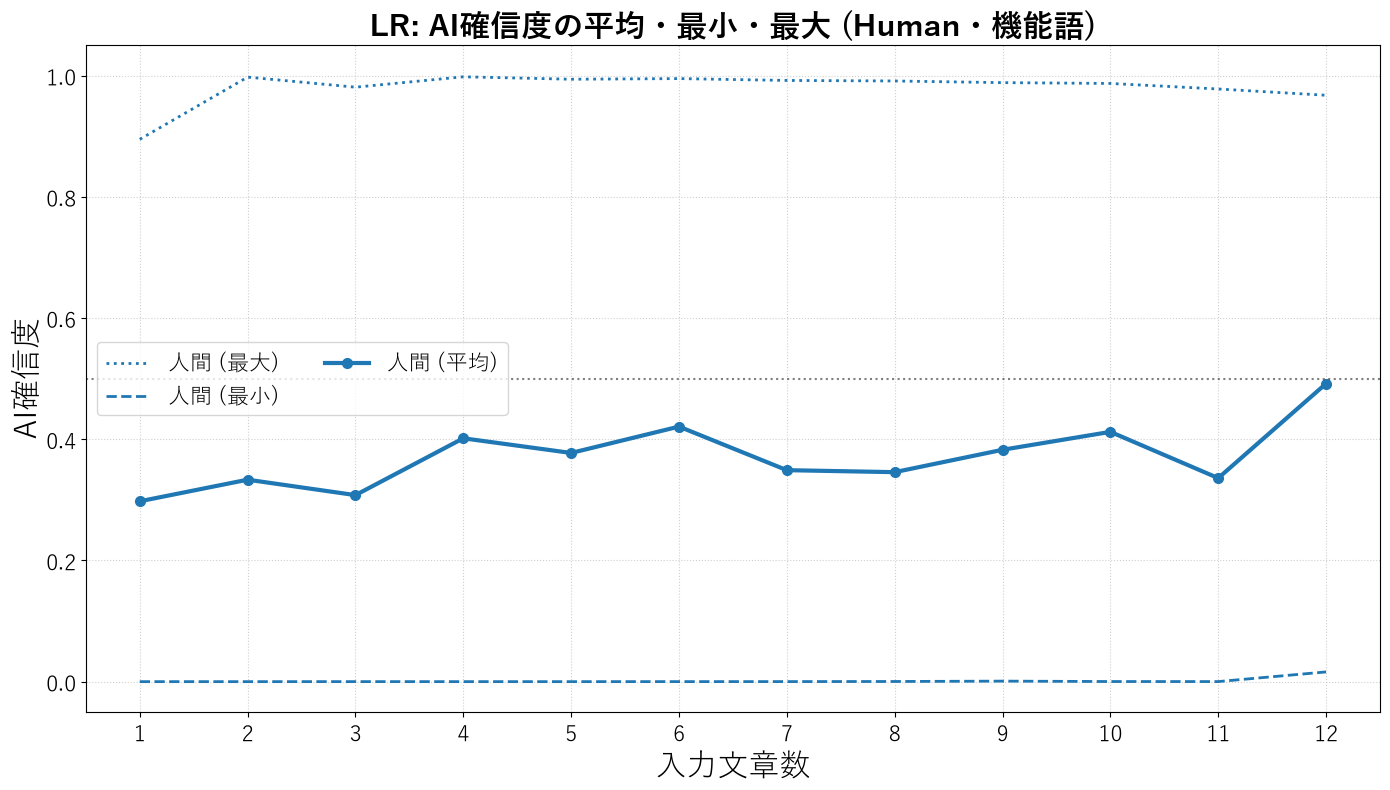

-> Qwen_LR_trajectory_Human_Content.png を保存しました。


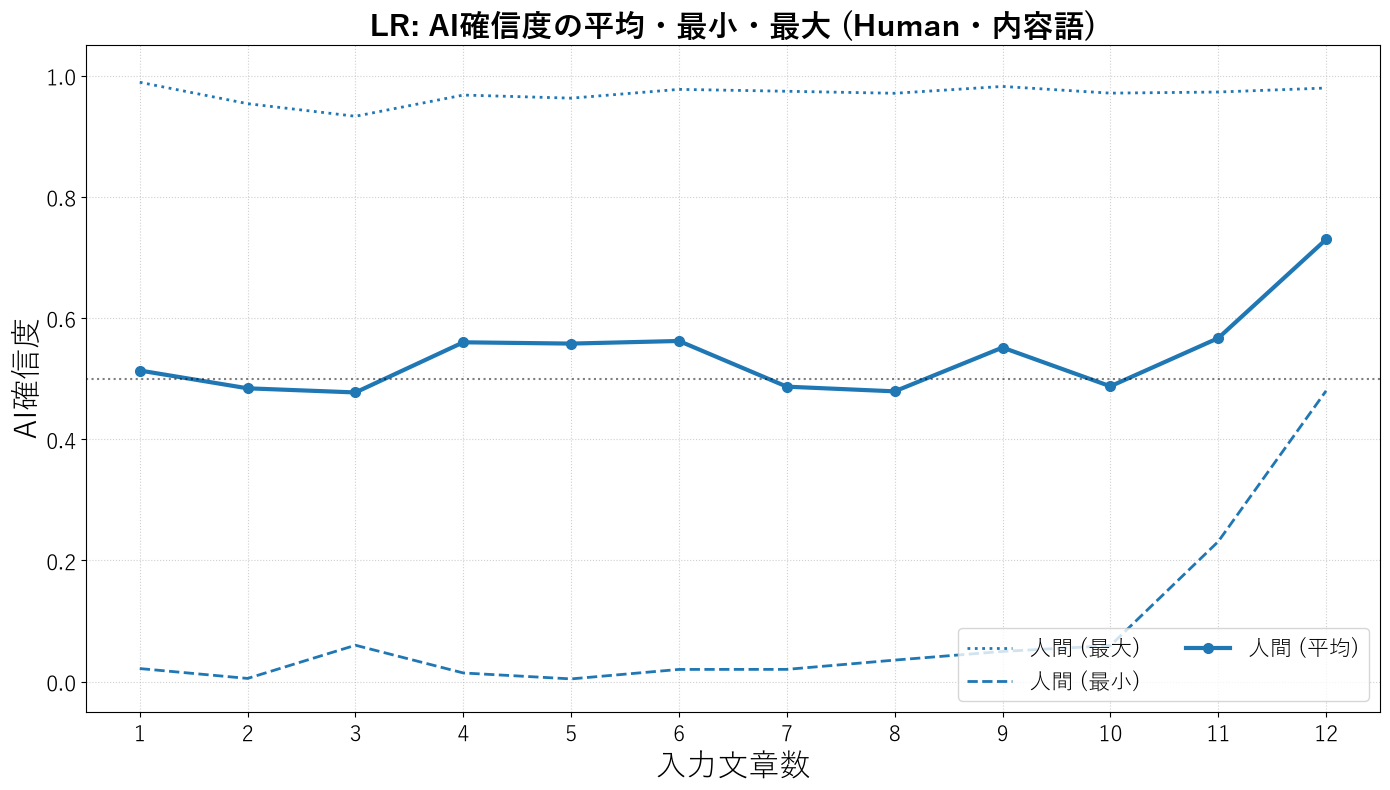

-> Qwen_LR_trajectory_Qwen_All.png を保存しました。


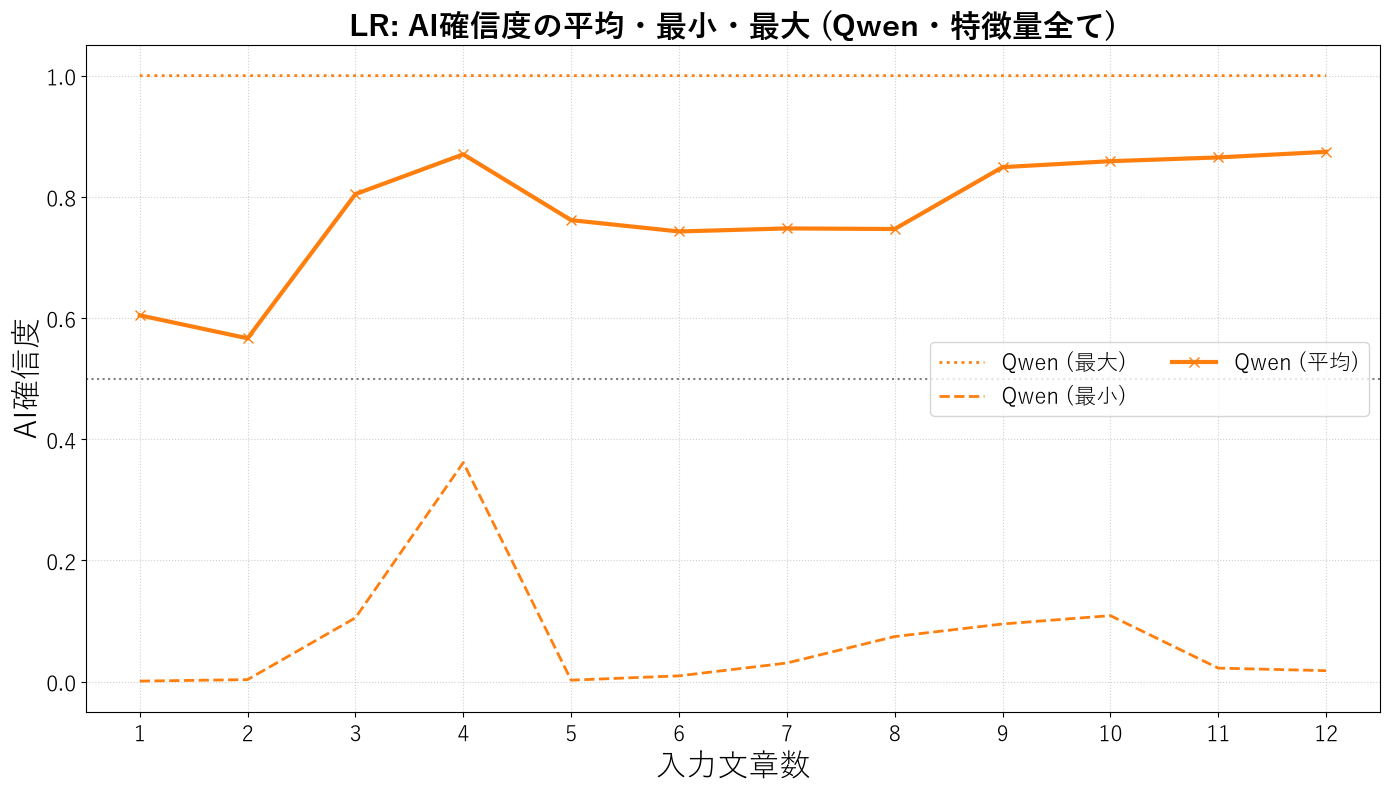

-> Qwen_LR_trajectory_Qwen_Function.png を保存しました。


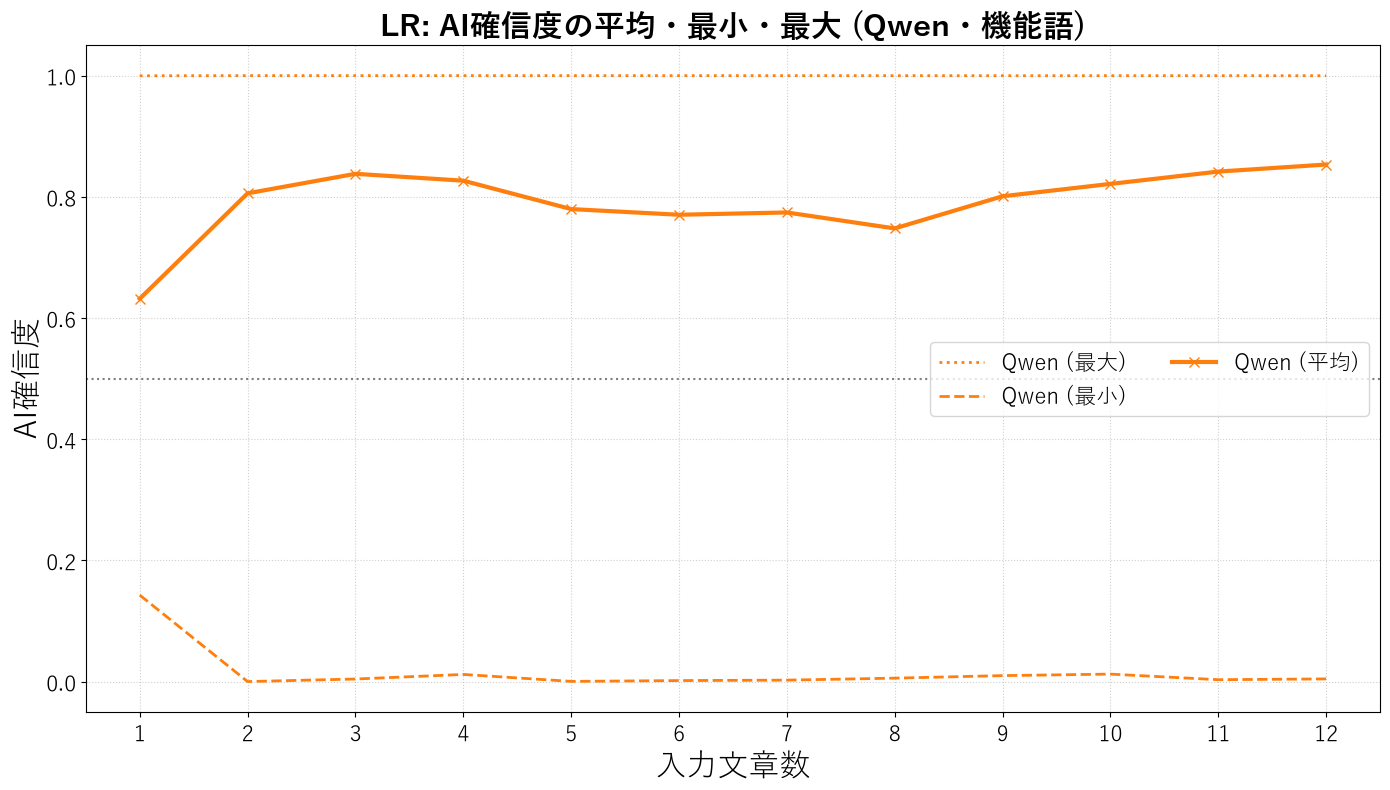

-> Qwen_LR_trajectory_Qwen_Content.png を保存しました。


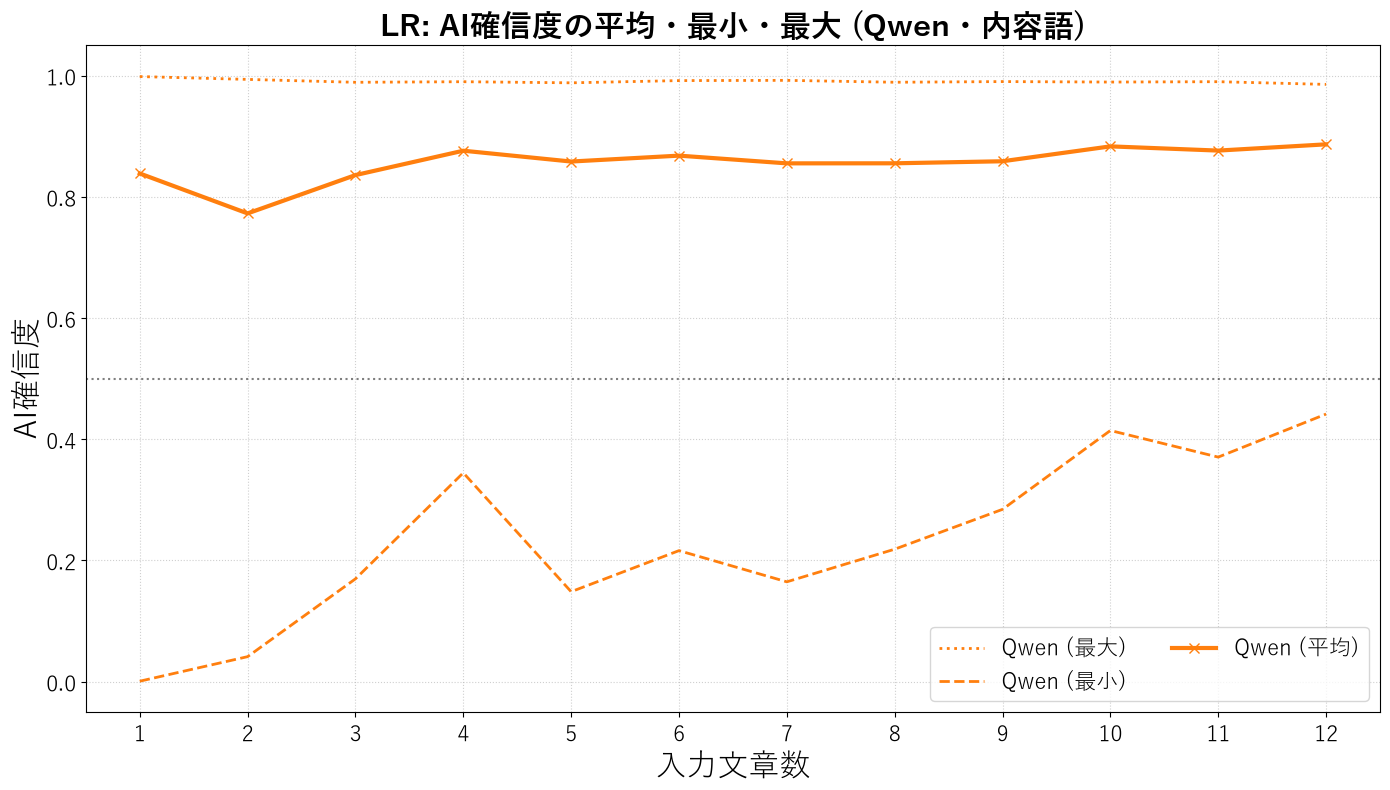

In [1]:

# ==========================================
# ラベルごとの平均・最小・最大AI確率を描画
# Qwen用LR版
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# 日本語フォント設定
plt.rcParams["font.family"] = ["Yu Gothic", "Meiryo", "MS Gothic"]
plt.rcParams["axes.unicode_minus"] = False
# ==========================================
# 1. 設定
# ==========================================

current_dir = r"C:\Users\Admin\2026-\one-sentence\Qwen"

feature_types = ["All", "Function", "Content"]

# 特徴量名の日本語マッピング
feature_names_ja = {
    "All": "特徴量全て",
    "Function": "機能語",
    "Content": "内容語"
}

# ==========================================
# 2. Human / Qwen ごとに描画
# ==========================================

for test_name in ["Human", "Qwen"]:

    for t in feature_types:

        csv_filename = f"Qwen_LR_{test_name}_{t}_results.csv"
        csv_path = os.path.join(current_dir, csv_filename)

        if not os.path.exists(csv_path):
            print(f"警告: {csv_filename} が見つからないためスキップします。")
            continue

        df = pd.read_csv(csv_path)

        # labelごとの平均・最小・最大を計算
        df_stats = (
            df.groupby(["label", "sent_order"])["AI確率"]
            .agg(["mean", "min", "max"])
            .reset_index()
        )

        fig, ax = plt.subplots(figsize=(14, 8))

        # ======================================
        # Human / Qwen の描画
        # ======================================

        # Human（人間の文章）
        human = (
            df_stats[
                (df_stats["label"] == 0) &
                (df_stats["sent_order"] <= 12)
            ]
            .sort_values("sent_order")
        )

        # Qwen（AI生成文章）
        ai = (
            df_stats[
                (df_stats["label"] == 1) &
                (df_stats["sent_order"] <= 12)
            ]
            .sort_values("sent_order")
        )

        # Human
        if not human.empty:
            ax.plot(
                human["sent_order"], human["max"],
                linestyle=":", linewidth=2,
                color="#1f77b4", label="人間 (最大)"
            )

            ax.plot(
                human["sent_order"], human["min"],
                linestyle="--", linewidth=2,
                color="#1f77b4", label="人間 (最小)"
            )

            ax.plot(
                human["sent_order"], human["mean"],
                marker="o", linestyle="-",
                linewidth=3, markersize=7,
                color="#1f77b4", label="人間 (平均)"
            )

        # Qwen
        if not ai.empty:
            ax.plot(
                ai["sent_order"], ai["max"],
                linestyle=":", linewidth=2,
                color="#ff7f0e", label="Qwen (最大)"
            )

            ax.plot(
                ai["sent_order"], ai["min"],
                linestyle="--", linewidth=2,
                color="#ff7f0e", label="Qwen (最小)"
            )

            ax.plot(
                ai["sent_order"], ai["mean"],
                marker="x", linestyle="-",
                linewidth=3, markersize=7,
                color="#ff7f0e", label="Qwen (平均)"
            )

        # ======================================
        # グラフの装飾
        # ======================================

        t_ja = feature_names_ja.get(t, t)

        ax.set_title(
            f"LR: AI確信度の平均・最小・最大 ({test_name}・{t_ja})",
            fontsize=22,
            fontweight="bold"
        )

        ax.set_xlabel("入力文章数", fontsize=22)
        ax.set_ylabel("AI確信度", fontsize=22)

        ax.tick_params(axis="both", labelsize=16)

        ax.set_xlim(0.5, 12.5)
        ax.set_ylim(-0.05, 1.05)

        ax.set_xticks(range(1, 13))

        ax.axhline(
            y=0.5,
            color="black",
            linestyle=":",
            linewidth=1.5,
            alpha=0.5
        )

        ax.grid(True, linestyle=":", alpha=0.6)

        ax.legend(
            fontsize=16,
            loc="best",
            ncol=2
        )

        plt.tight_layout()

        # ======================================
        # 保存
        # ======================================

        output_png = (
            f"Qwen_LR_trajectory_{test_name}_{t}.png"
        )

        plt.savefig(
            os.path.join(current_dir, output_png),
            dpi=150,
            bbox_inches="tight"
        )

        print(f"-> {output_png} を保存しました。")

        plt.show()
        plt.close(fig)


In [7]:
import os
import pandas as pd

current_dir = r"C:\Users\Admin\2026-\one-sentence\Gemini"

for t in ["All", "Function", "Content"]:

    csv_path = os.path.join(
        current_dir,
        f"Gemini_LR_Human_{t}_results.csv"
    )

    df = pd.read_csv(csv_path)

    print(f"\n===== {t} =====")
    print("最大文章数:", df["sent_order"].max())

    print(
        df.groupby("doc_id")["sent_order"].max()
    )


===== All =====
最大文章数: 13
doc_id
Human_test_Human_text_01.txt     9
Human_test_Human_text_02.txt    13
Human_test_Human_text_03.txt     9
Human_test_Human_text_04.txt    11
Human_test_Human_text_05.txt    10
Human_test_Human_text_06.txt    10
Human_test_Human_text_07.txt     8
Human_test_Human_text_08.txt    10
Human_test_Human_text_09.txt    13
Human_test_Human_text_10.txt    10
Name: sent_order, dtype: int64

===== Function =====
最大文章数: 13
doc_id
Human_test_Human_text_01.txt     9
Human_test_Human_text_02.txt    13
Human_test_Human_text_03.txt     9
Human_test_Human_text_04.txt    11
Human_test_Human_text_05.txt    10
Human_test_Human_text_06.txt    10
Human_test_Human_text_07.txt     8
Human_test_Human_text_08.txt    10
Human_test_Human_text_09.txt    13
Human_test_Human_text_10.txt    10
Name: sent_order, dtype: int64

===== Content =====
最大文章数: 13
doc_id
Human_test_Human_text_01.txt     9
Human_test_Human_text_02.txt    13
Human_test_Human_text_03.txt     9
Human_test_Human_text_